# **CNN**

실제 이미지 데이터 없이, **직접 만든 간단한 텐서**로 Conv2d, Pooling, Stride, Padding의 동작을 확인합니다.

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

In [2]:
x = torch.randn(1, 3, 32, 32)
print(x)
x.shape

tensor([[[[-0.5610, -1.0263,  0.2886,  ...,  1.4773,  1.4474, -0.7499],
          [-0.3103, -0.8806,  1.0207,  ...,  0.1229,  0.8091,  1.8334],
          [-0.7674, -1.1251,  0.1157,  ..., -0.6419,  1.9032,  0.5247],
          ...,
          [-0.1909,  1.5872,  0.0405,  ...,  0.7412,  0.7295, -1.2167],
          [-0.2636,  0.9190, -0.3058,  ..., -0.0183, -0.3028, -0.6325],
          [ 0.0351,  0.1204, -0.3663,  ..., -0.1636, -0.4787, -0.4482]],

         [[-0.5646,  0.0822,  0.8284,  ...,  1.2964,  1.9398, -1.6113],
          [ 0.9120, -1.0080, -0.6348,  ...,  0.0827, -0.8526,  0.4948],
          [-0.4150,  1.7794, -1.6804,  ..., -1.1776,  0.5876,  1.1372],
          ...,
          [ 1.0171, -0.9764, -0.0074,  ...,  0.3272, -2.5731,  0.1941],
          [-0.1703,  0.2112, -0.5998,  ...,  0.0829, -0.0333,  0.5862],
          [ 0.0758,  1.2815, -1.6119,  ...,  0.1526,  1.7145,  0.3439]],

         [[-2.1701,  0.7023,  0.6743,  ..., -0.3145,  0.1476, -0.6777],
          [ 1.6076, -1.4064,  

torch.Size([1, 3, 32, 32])

In [3]:
conv1 = nn.Conv2d(3, 16, 3)             # 커널 개수 16개 / 커널 사이즈 3 * 3
conv2 = nn.Conv2d(16, 32, 3)            # 커널 개수 32개 / 커널 사이즈 3 * 3

In [4]:
x = conv1(x)
print(x.shape)

torch.Size([1, 16, 30, 30])


In [5]:
x = conv2(x)
print(x.shape)

torch.Size([1, 32, 28, 28])


## **1. 이미지 텐서 기본 구조**

PyTorch에서 이미지는 항상 `(배치, 채널, H, W)` 형태입니다.

| 차원 | 의미 | 예시 |
|------|------|------|
| N (배치) | 한 번에 처리하는 이미지 수 | 1 |
| C (채널) | 흑백=1, 컬러=3 | 1 |
| H (높이) | 픽셀 행 수 | 6 |
| W (너비) | 픽셀 열 수 | 6 |

**Q1. 아래 6×6 이미지지를 (1, 1, 6, 6)의 tensor로 변환한다.**

In [6]:
#code here
img = torch.tensor([
    [0, 0, 0, 1, 1, 1],
    [0, 0, 0, 1, 1, 1],
    [0, 0, 0, 1, 1, 1],
    [1, 1, 1, 0, 0, 0],
    [1, 1, 1, 0, 0, 0],
    [1, 1, 1, 0, 0, 0],
], dtype=torch.float32)
img.shape

torch.Size([6, 6])

In [7]:
x = img.reshape(1, 1, 6, 6)
x.shape

torch.Size([1, 1, 6, 6])

**Q2. matplotlib으로 이미지를 시각화해보자.**
- 흑백으로 나타나도록 한다.

```
plt.imshow(img, cmap="gray")
```

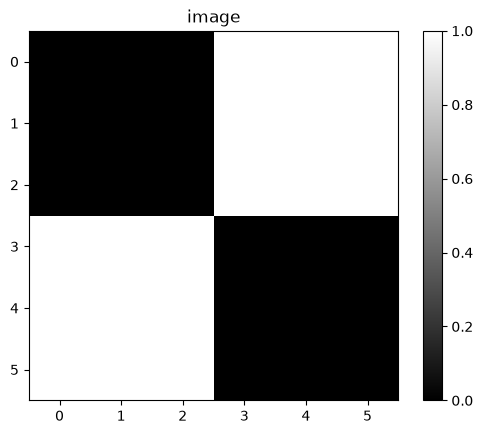

In [8]:
plt.imshow(img, cmap='gray')
plt.title('image')
plt.colorbar()
plt.show()

## **2. Conv2d**

필터(커널)를 이미지 위에서 슬라이딩하며 **내적(dot product)** 을 계산합니다.

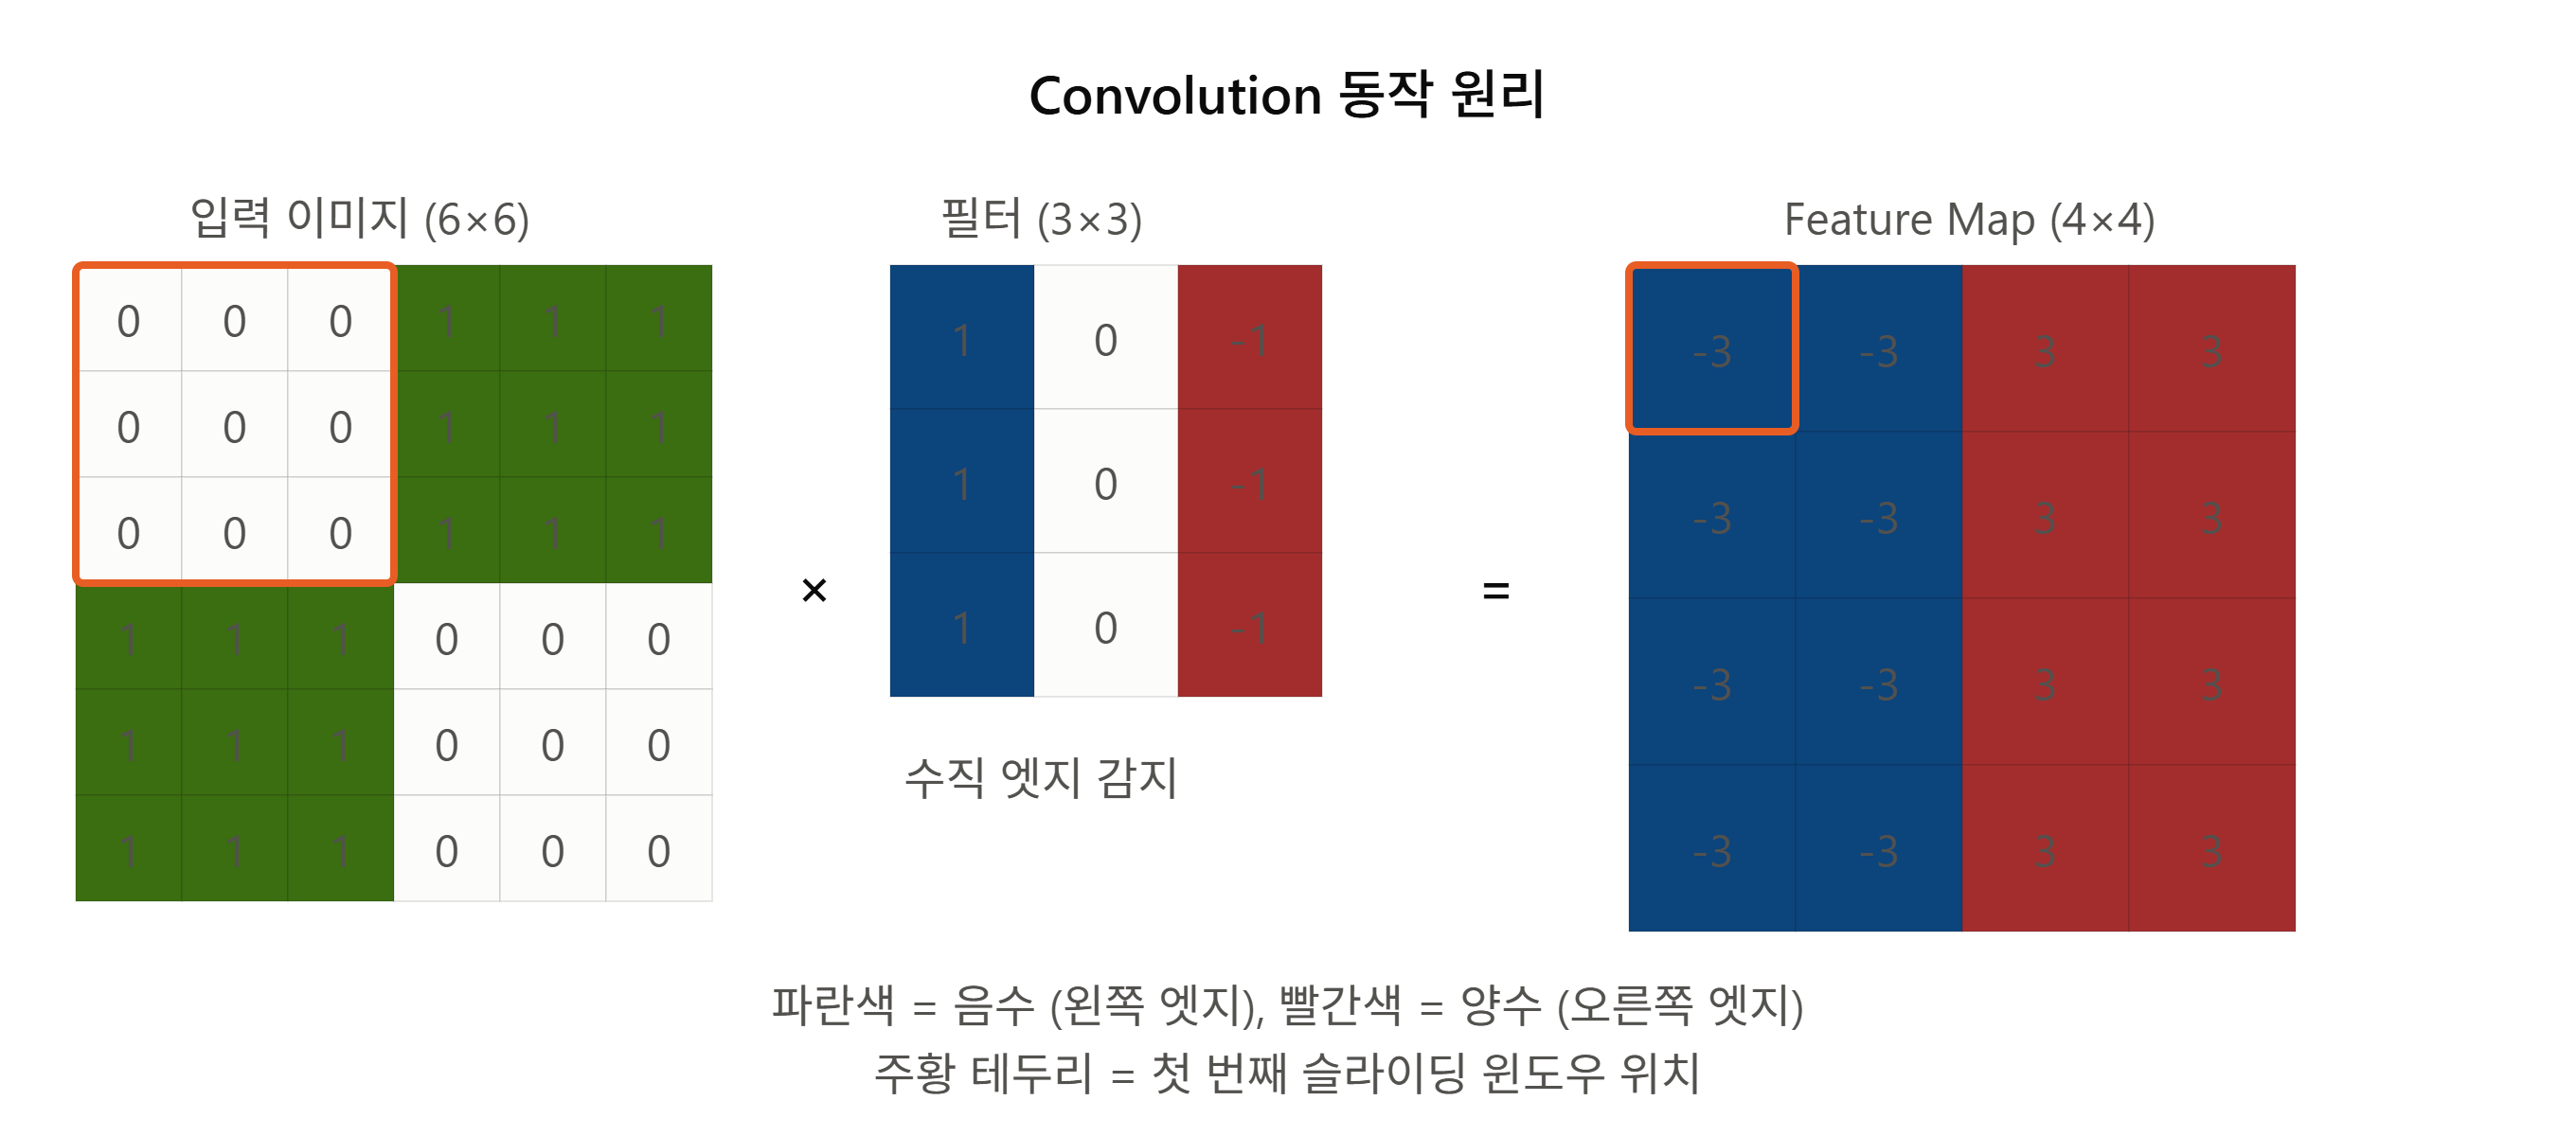

**출력 크기 공식**

$$\text{출력} = \frac{\text{입력} - \text{kernel} + 2 \times \text{padding}}{\text{stride}} + 1$$

**Q1. 기본 Conv2d를 적용하고 출력 shape를 확인해보자.**

- in_channels=1,
- out_channels=1,
- kernel_size=3
- padding=0,
- stride=1 (기본값)

예상 출력 크기: $(6 - 3 + 0) / 1 + 1 = 4$

In [9]:
conv = nn.Conv2d(
    in_channels=1,
    out_channels=1,
    kernel_size=3,
    padding=0,
    stride=1
)

In [10]:
with torch.no_grad():
  out = conv(x)

In [11]:
print(out.shape)

torch.Size([1, 1, 4, 4])


**Q2. conv로 나온 결과물을 시각화해보자.**

- flatten()후 4 x 4로 다시 reshape하여 시각화하면 된다.

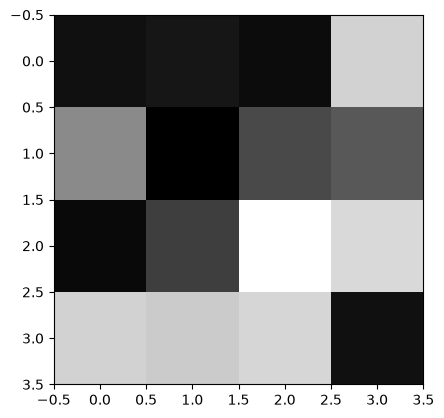

In [12]:
plt.imshow(out.flatten().reshape(4,4), cmap='gray')
plt.show()

## **3. kernel(필터) 체험**

out_channels=N 이면 **N개의 다른 필터**를 동시에 학습합니다.  
- 각 필터는 서로 다른 특징(수직 엣지, 수평 엣지, 곡선 등)을 감지합니다.

**Q1. out_channels=4인 conv2d 객체를 만든다.**

In [13]:
# code here
conv_multi = nn.Conv2d(
    in_channels=1,
    out_channels=4,
    kernel_size=3,
    padding=0,
    stride=1
)

**Q2. 4개의 필터를 직접 생성한다.**

In [14]:
# 필터 4개를 의미 있는 패턴으로 설정
with torch.no_grad():
    # 수직 엣지
    conv_multi.weight[0] = torch.tensor([[[ 1.,  0., -1.],
                                           [ 1.,  0., -1.],
                                           [ 1.,  0., -1.]]])
    # 수평 엣지
    conv_multi.weight[1] = torch.tensor([[[ 1.,  1.,  1.],
                                           [ 0.,  0.,  0.],
                                           [-1., -1., -1.]]])
    # 샤프닝
    conv_multi.weight[3] = torch.tensor([[[ 0., -1.,  0.],
                                           [-1.,  5., -1.],
                                           [ 0., -1.,  0.]]])
     # Edge Detection
    conv_multi.weight[3] = torch.tensor([[[ -1., -1.,  -1.],
                                           [-1.,  8., -1.],
                                           [ -1., -1.,  -1.]]])
    conv_multi.bias.zero_()
    # 모든 bias를 0으로 초기화 -> 모델이 랜덤으로 가지는 가중치를 0으로 바꿔 단순히 필터의 결과만 보기 위함이다.
    # 이후 과정에서는 안해도 된다.(안 해야 한다.)

**Q3. conv2d 객체에 이미지를 넣어 결과를 낸다.**

In [15]:
with torch.no_grad():
    out_multi = conv_multi(x)   # (1, 4, 6, 6)

**Q3. 필터를 씌운 feature map을 시각화한다.**

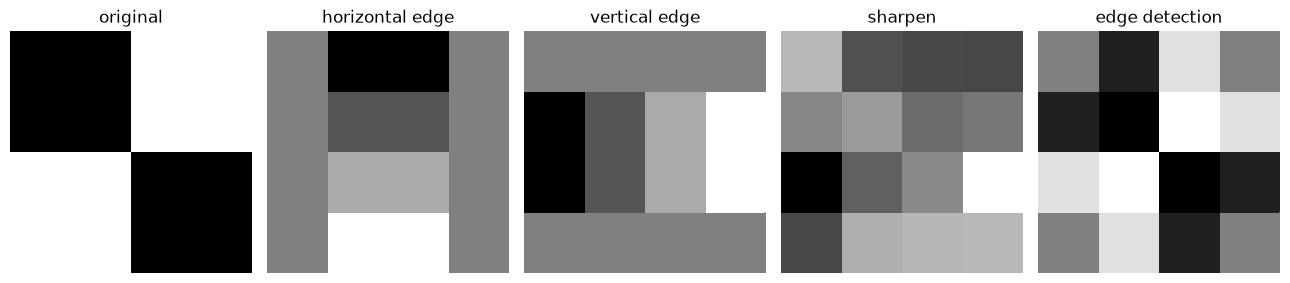

In [16]:
titles = ['horizontal edge', 'vertical edge', 'sharpen', 'edge detection']
fig, axes = plt.subplots(1, 5, figsize=(13, 3))
axes[0].imshow(x[0, 0].numpy(), cmap='gray'); axes[0].set_title('original'); axes[0].axis('off')
for i in range(4):
    axes[i+1].imshow(out_multi[0, i].numpy(), cmap='gray')
    axes[i+1].set_title(titles[i])
    axes[i+1].axis('off')
plt.tight_layout(); plt.show()

## **4. Padding**

Padding은 이미지 경계에 0을 추가한다.

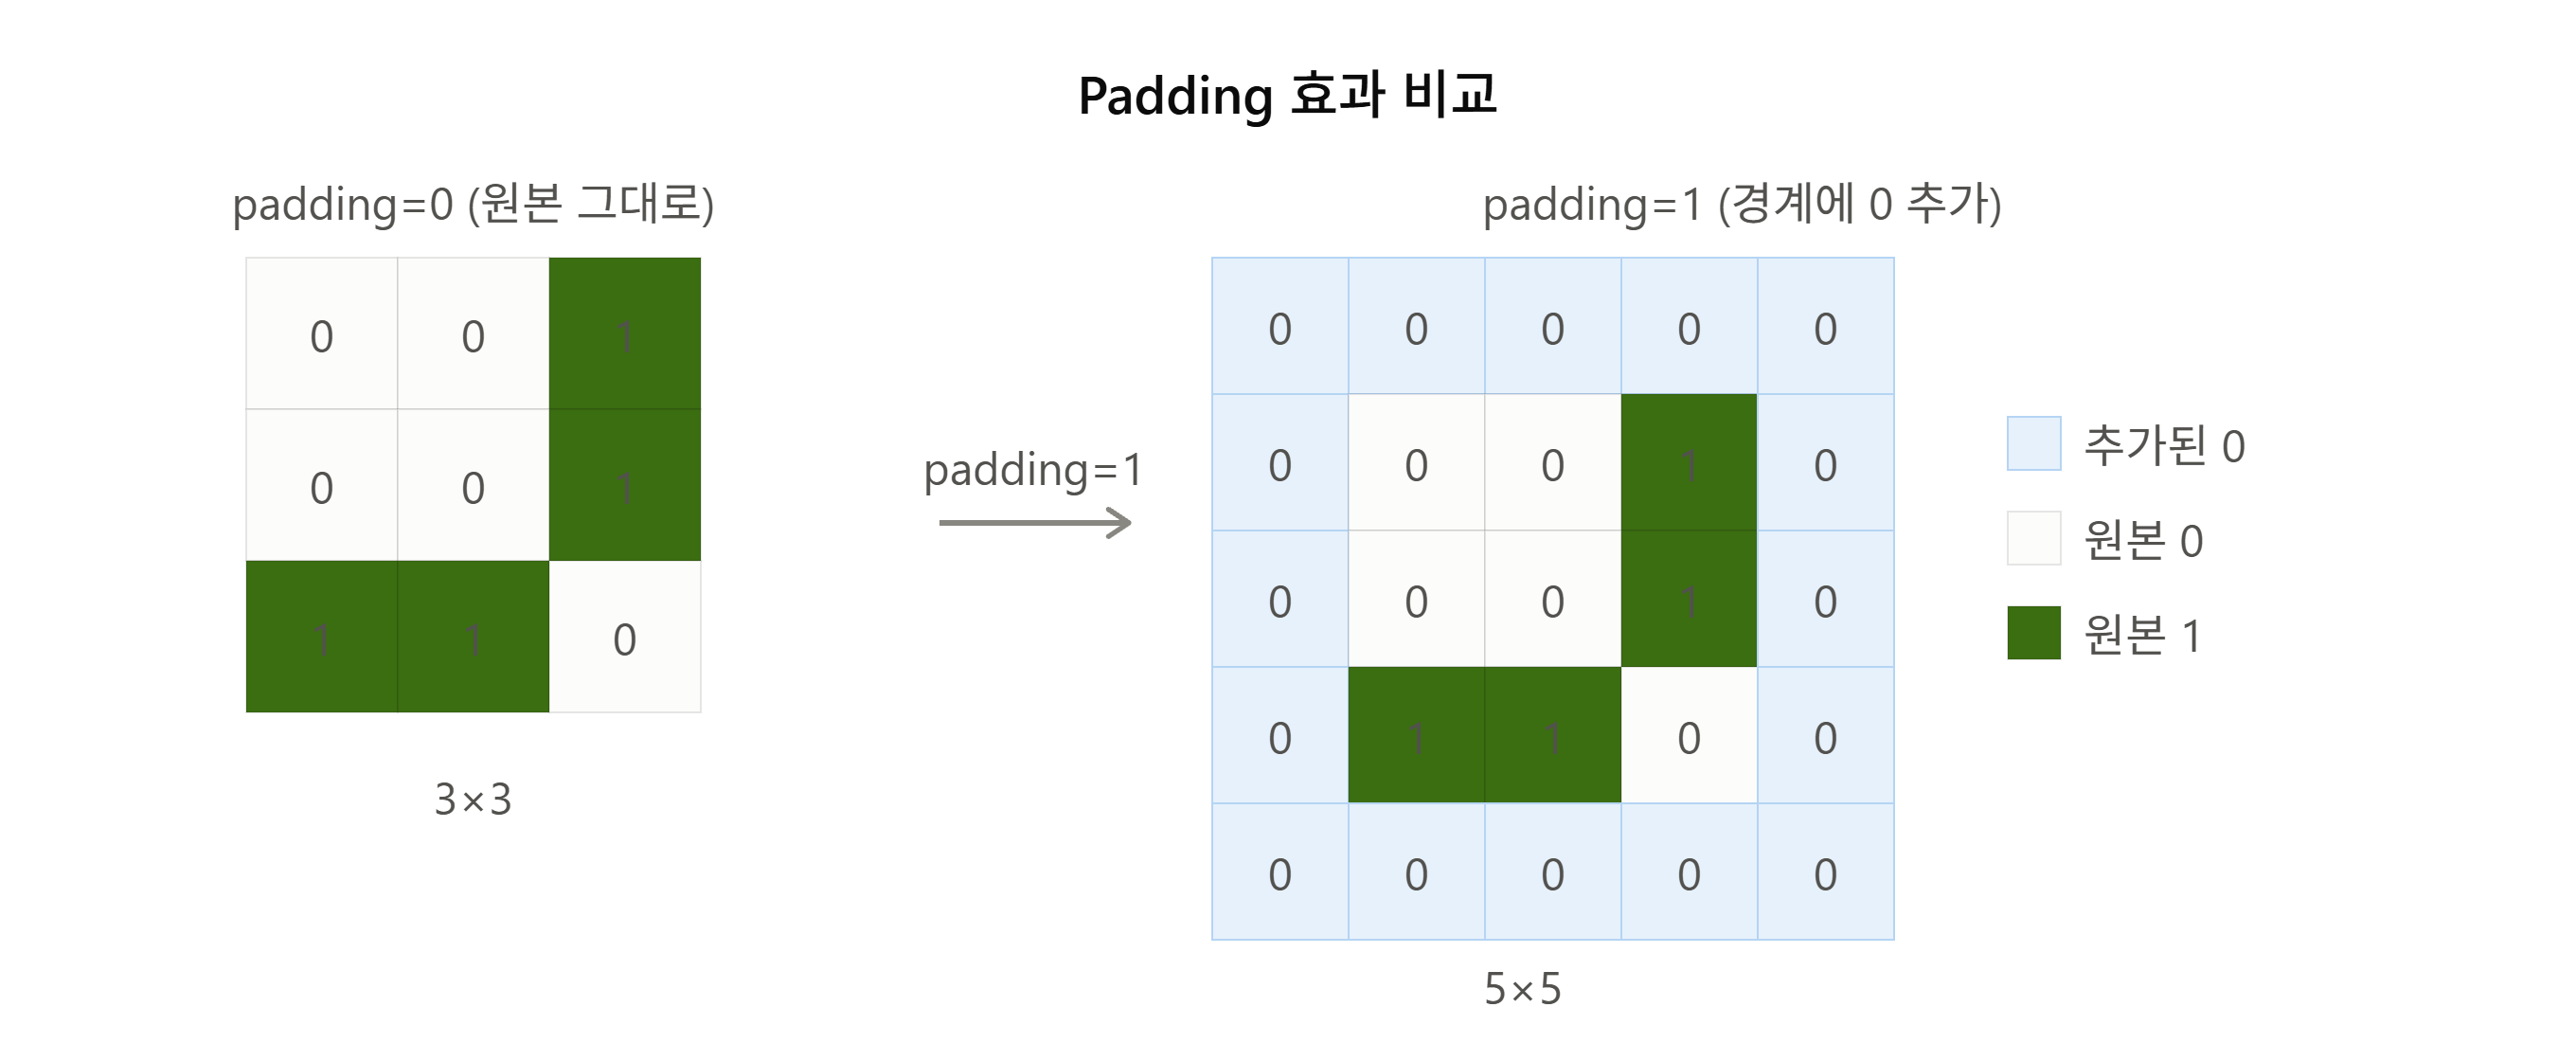

**padding=1, kernel=3** 이면 출력 크기 = 입력 크기 (크기 유지)


$$\frac{6 - 3 + 2 \times 1}{1} + 1 = 6$$

**Q1. padding=0과 padding=1인 conv2d 객체를 만든다.**
- in_channels=1
- out_channels=1
- kernel_size=3
- stride=1

In [17]:
conv_p0 = nn.Conv2d(
    in_channels=1,
    out_channels=1,
    kernel_size=3,
    padding=0,
    stride=1
    )

In [18]:
conv_p1 = nn.Conv2d(
    in_channels=1,
    out_channels=1,
    kernel_size=3,
    padding=1,
    stride=1
    )

**Q2. 두 객체에 이미지 데이터를 넣어 feature map을 뽑는다.**

In [19]:
with torch.no_grad():
    out_p0 = conv_p0(x)
    out_p1 = conv_p1(x)

**Q3. 각각의 결과의 shape를 출력하고, 시각화한다.**

torch.Size([1, 1, 4, 4])


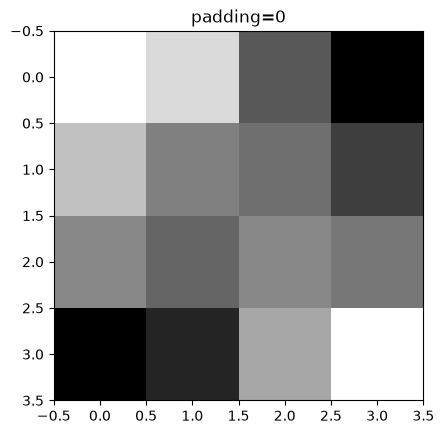

In [20]:
print(out_p0.shape)
plt.title("padding=0")
plt.imshow(out_p0.flatten().reshape(4,4), cmap='gray')
plt.show()

torch.Size([1, 1, 6, 6])


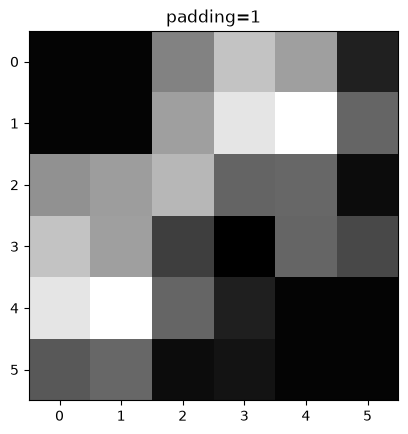

In [21]:
print(out_p1.shape)
plt.title("padding=1")
plt.imshow(out_p1.flatten().reshape(6,6), cmap='gray')
plt.show()

## **5. Stride**

Stride는 필터가 한 번에 이동하는 간격이다.

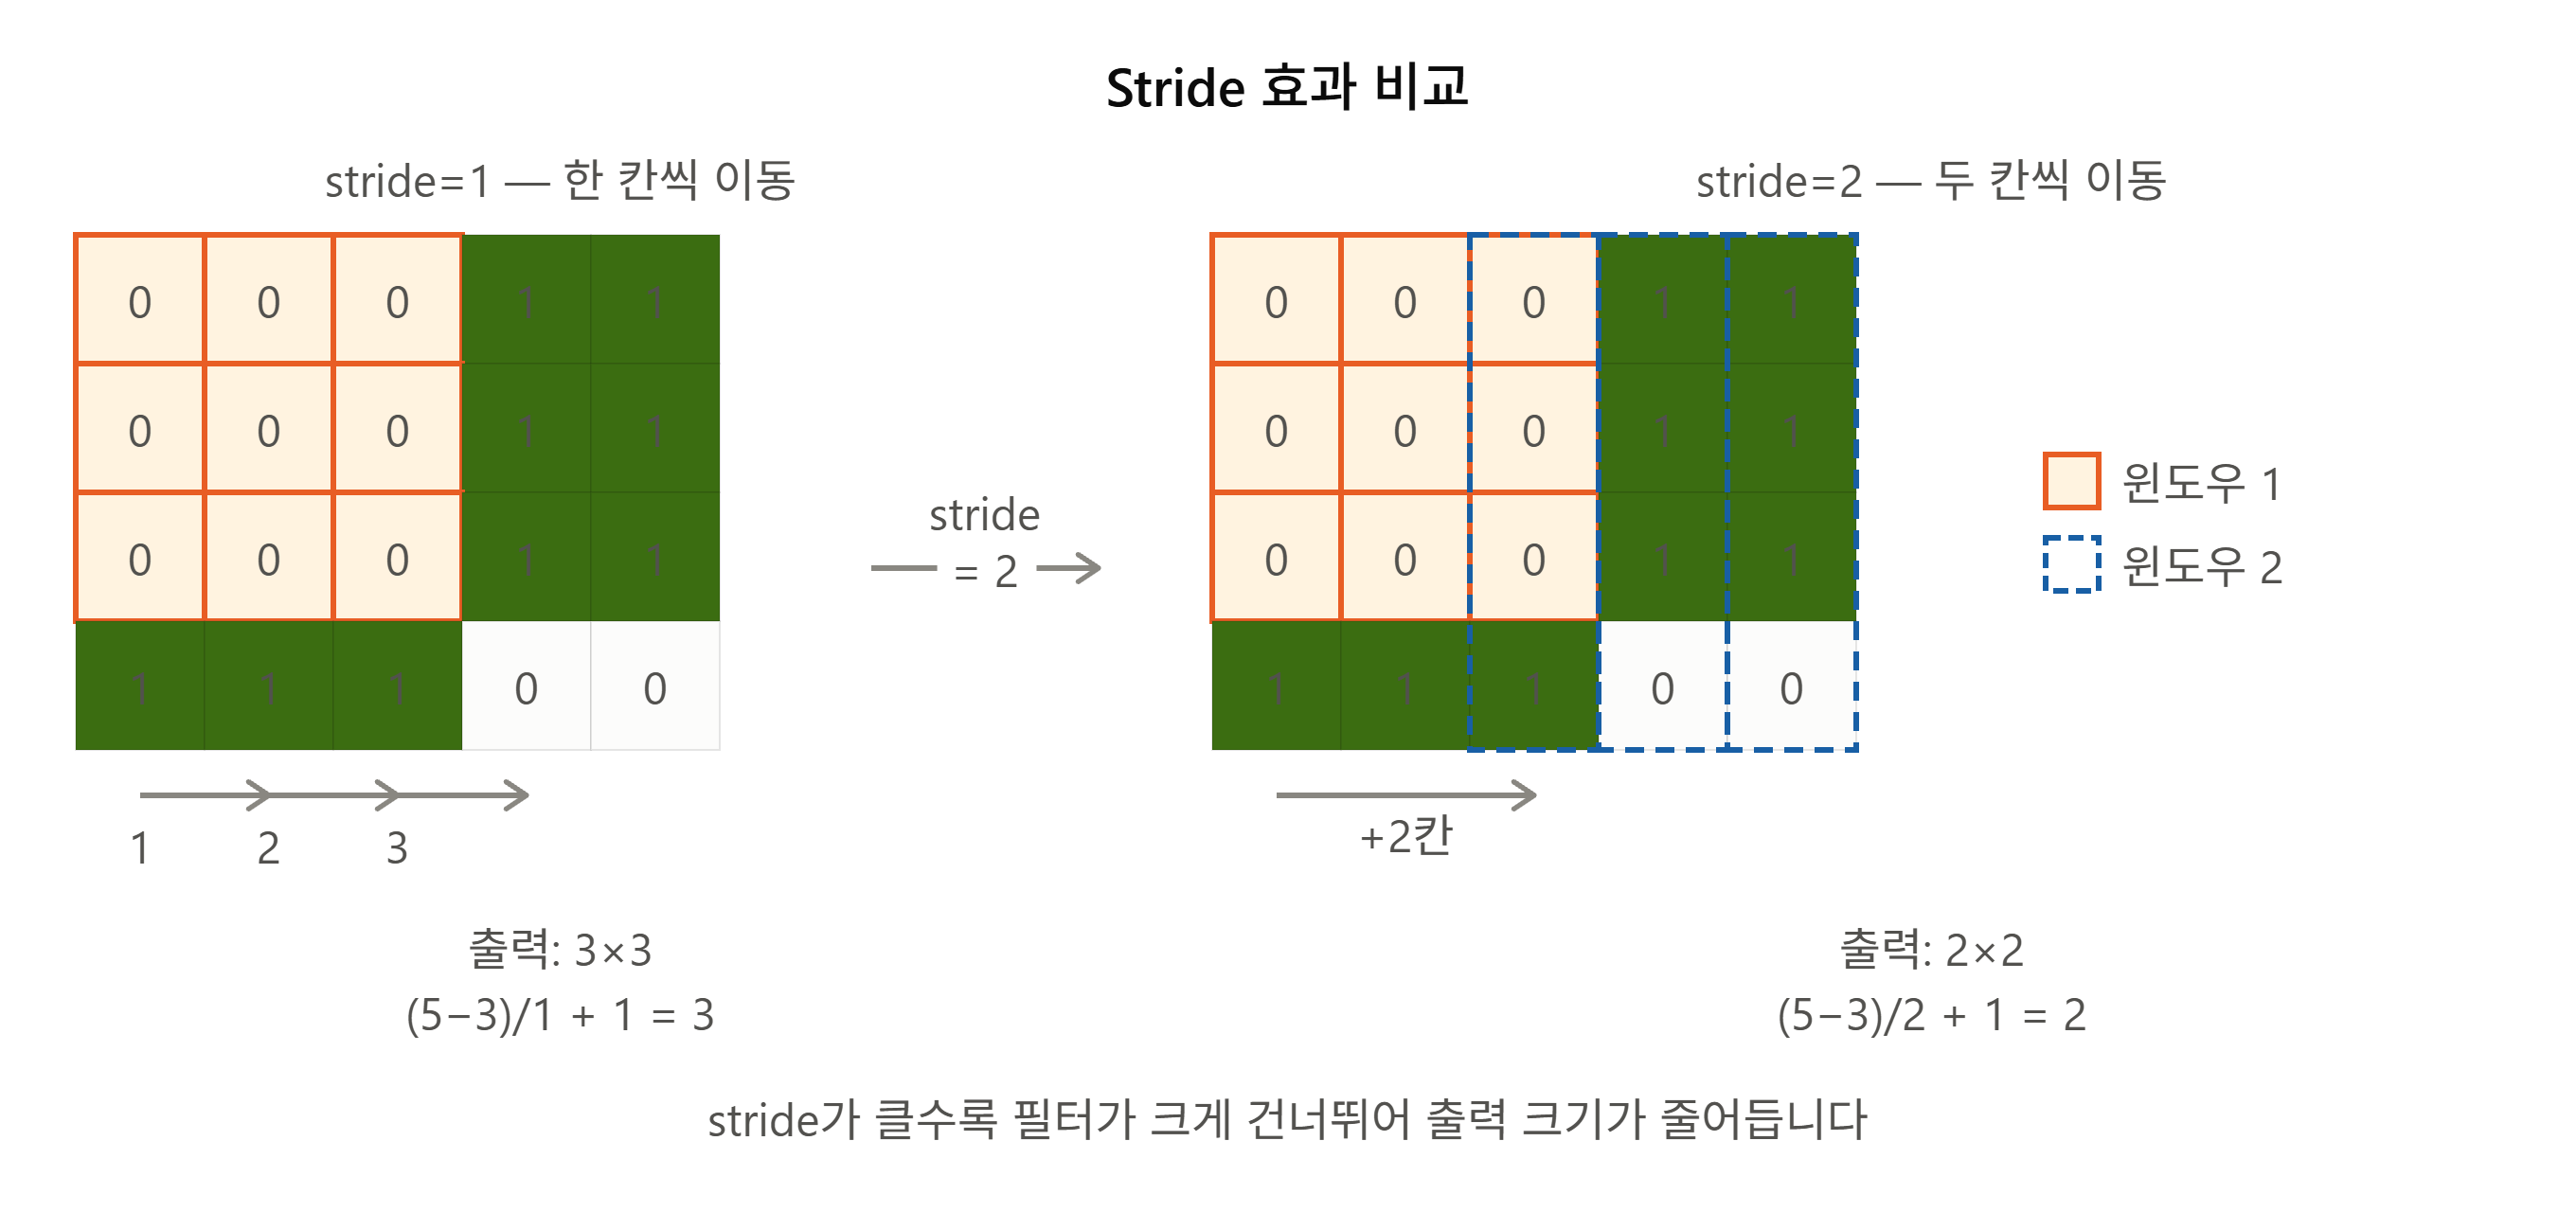

**Q1. stride=1과 stride=2인 conv2d 객체를 만든다.**
- in_channels=1
- out_channels=1
- kernel_size=3
- padding=1

In [22]:
conv_s1 = nn.Conv2d(
    in_channels=1,
    out_channels=1,
    kernel_size=3,
    padding=1,
    stride=1
    )

In [23]:
conv_s2 = nn.Conv2d(
    in_channels=1,
    out_channels=1,
    kernel_size=3,
    padding=1,
    stride=2
    )

**Q2. 두 객체에 이미지 데이터를 넣어 feature map을 뽑는다.**

In [24]:
with torch.no_grad():
    out_s1 = conv_s1(x)
    out_s2 = conv_s2(x)

**Q3. 각각의 결과의 shape를 출력하고, 시각화한다.**

torch.Size([1, 1, 6, 6])


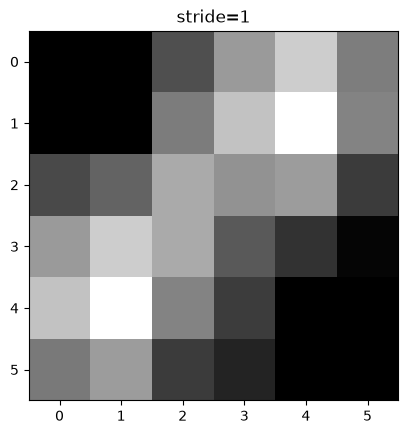

In [25]:
print(out_s1.shape)
plt.title("stride=1")
plt.imshow(out_s1.flatten().reshape(6,6), cmap='gray')
plt.show()

torch.Size([1, 1, 3, 3])


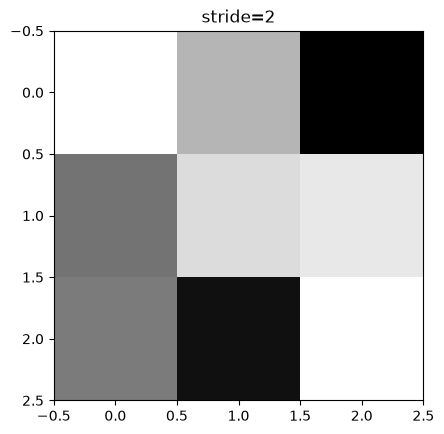

In [26]:
print(out_s2.shape)
plt.title("stride=2")
plt.imshow(out_s2.flatten().reshape(3,3), cmap='gray')
plt.show()

## **6. MaxPooling**

각 영역에서 **최댓값만** 남기고 나머지는 버린다.

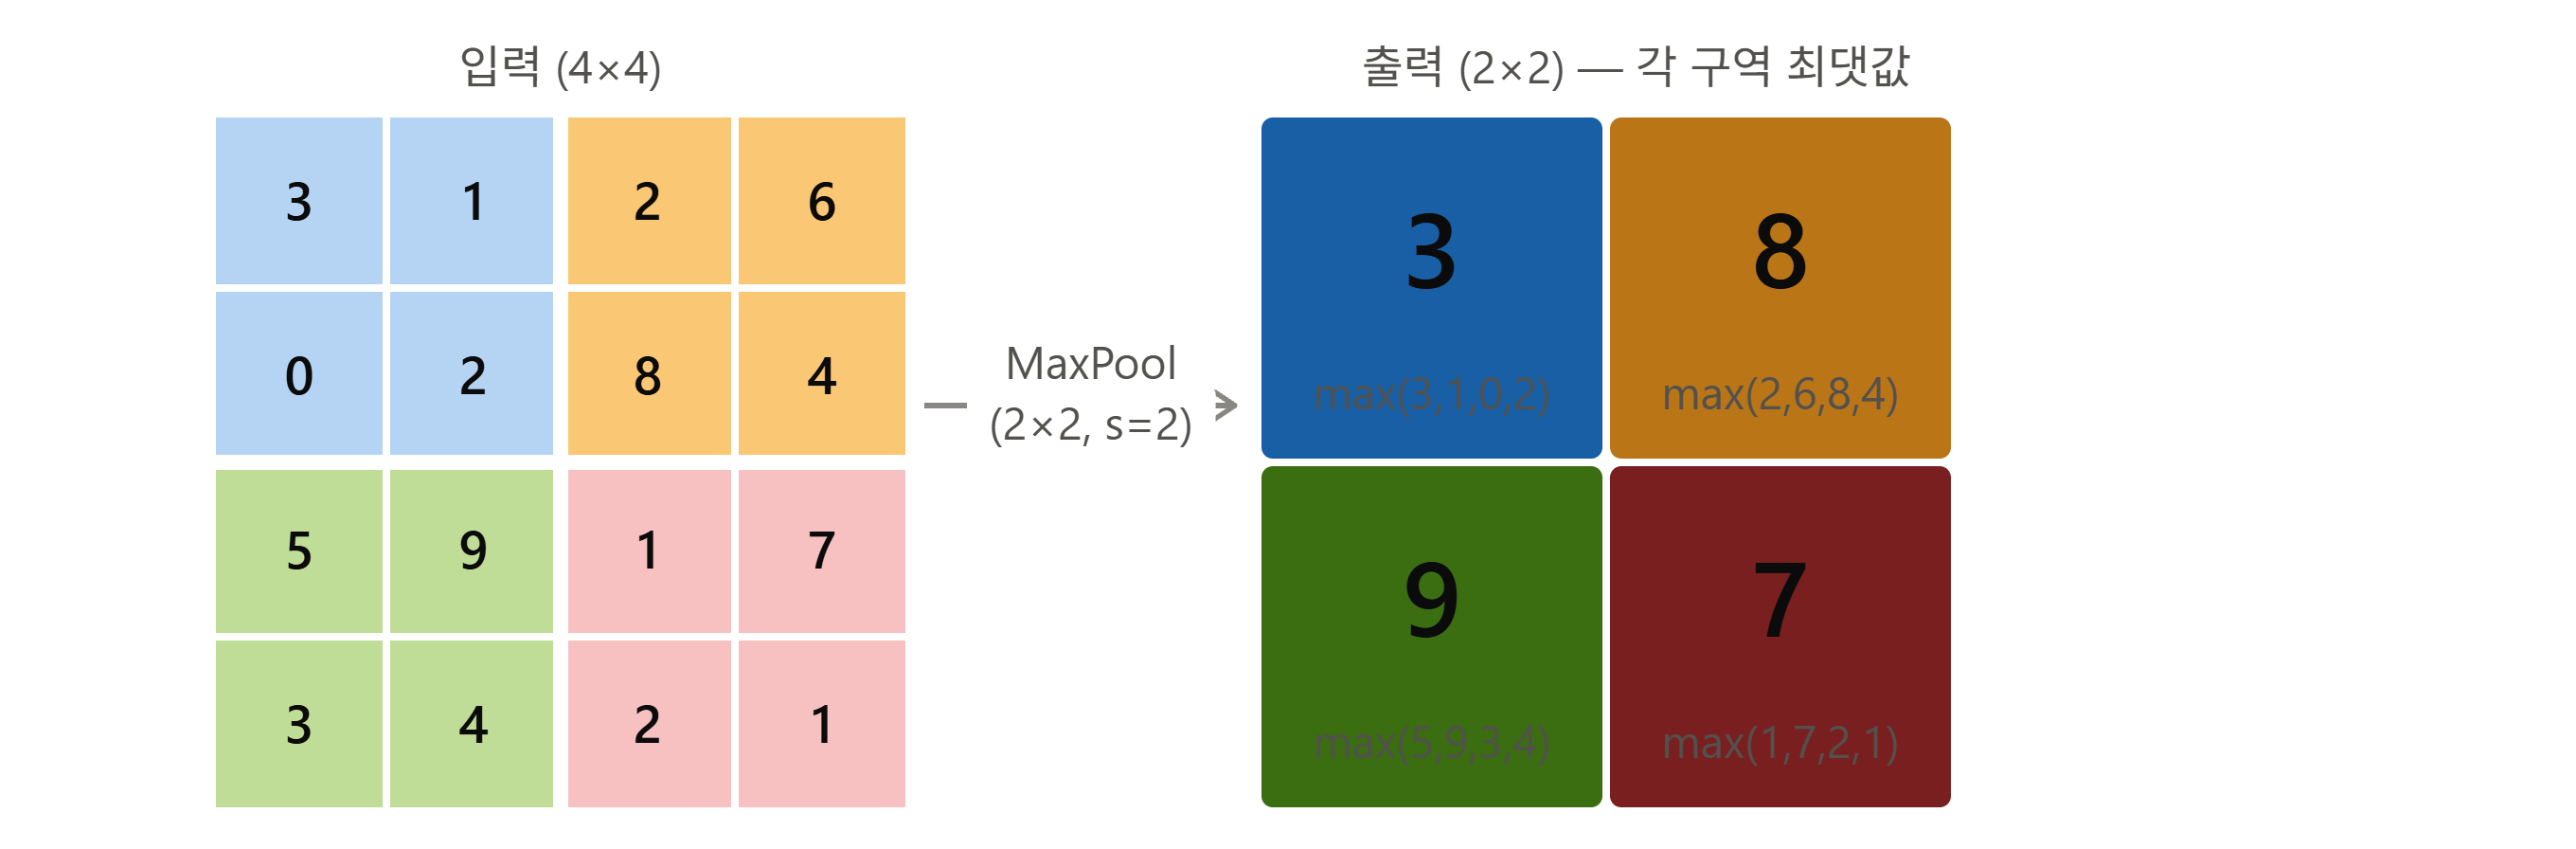

In [27]:
# feature map 예시
fm = torch.tensor([[
    [[ 3.,  1.,  2.,  6.],
     [ 0.,  2.,  8.,  4.],
     [ 5.,  9.,  1.,  7.],
     [ 3.,  4.,  2.,  1.]]]
])

**Q1. MaxPool2d 객체를 만든다.**

```
nn.Maxpool2d(kernel_size, stride)
```

- kernel_size : 2
- stride : 2

In [28]:
pool = nn.MaxPool2d(kernel_size=2, stride=2)

**Q2. 주어진 feature map을 pooling한 결과의 shape를 출력한다.**

In [29]:
pf = pool(fm)

In [30]:
print(pf.shape)

torch.Size([1, 1, 2, 2])


**Q3. 다시 x 데이터를 활용해보자.**
- 3단계에서 만든 conv2d 객체에 이미지를 넣은 후, max pooling을 한 결과를 내보자.


In [31]:
with torch.no_grad():
    after_conv = conv_multi(x)   # (1, 4, 6, 6)
    after_pool = pool(after_conv) # (1, 4, 3, 3)

**Q4. 그리고 pooling된 각 feature map들을 시각화해보자.**

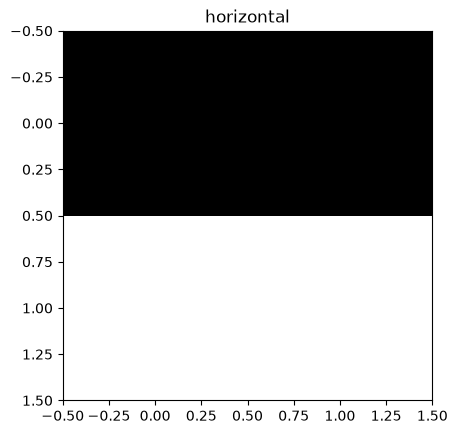

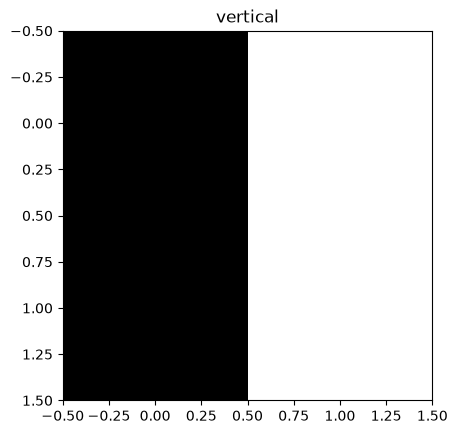

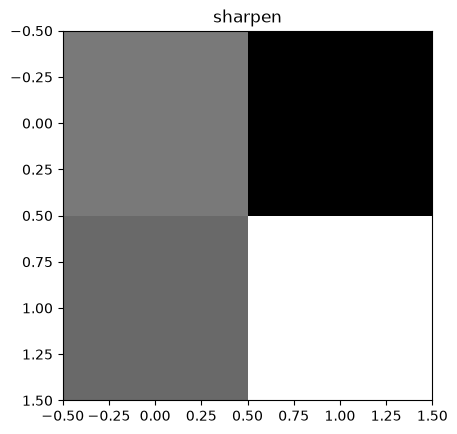

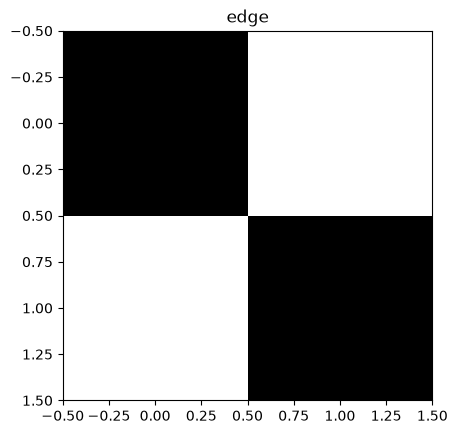

In [32]:
titles=['horizontal', 'vertical', 'sharpen', 'edge']
for i in range(4):
  plt.title(titles[i])
  plt.imshow(after_pool[0,i], cmap="gray")
  plt.show()